In [10]:
# PHYS 311
# LAB 6 - SPINNING & ROLLING OBJECTS
# Alexander Berry
# September 29, 2026

# IMPORT TOOLS

import numpy as np
import matplotlib.pyplot as plt

# Physical constants and rod properties
m = 1.0       # mass of rod (kg)
L = 1.0       # length of rod (m)
g = 9.81      # gravitational acceleration (m/s^2)

d = L / 2     # distance from center of mass to end of rod (m)

## Part A - The Physical Pendulum

In this section, we model the motion of a uniform rod pivoting about one end under the influence of gravity using rotational dynamics as well as the Euler-Cromer integration method.

Furthermore, we define the gravitational torque and implement the rotational Euler-Cromer integrator. We then plot the simulations and compare the numerical motions to the small-angle prediction.

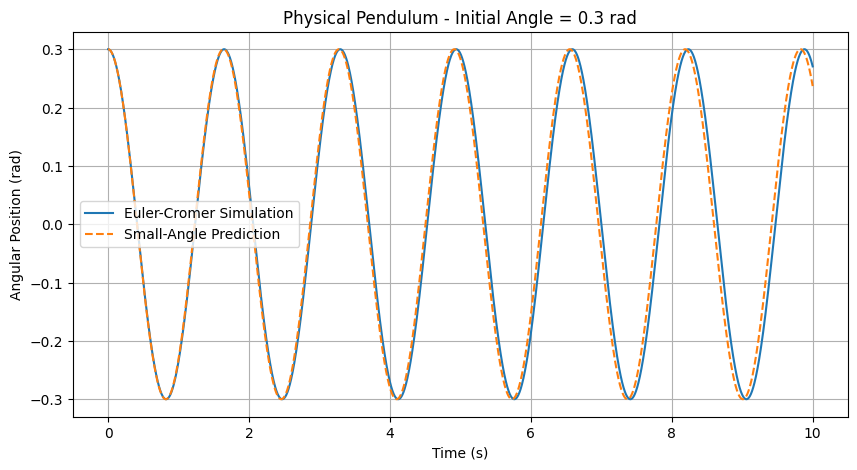

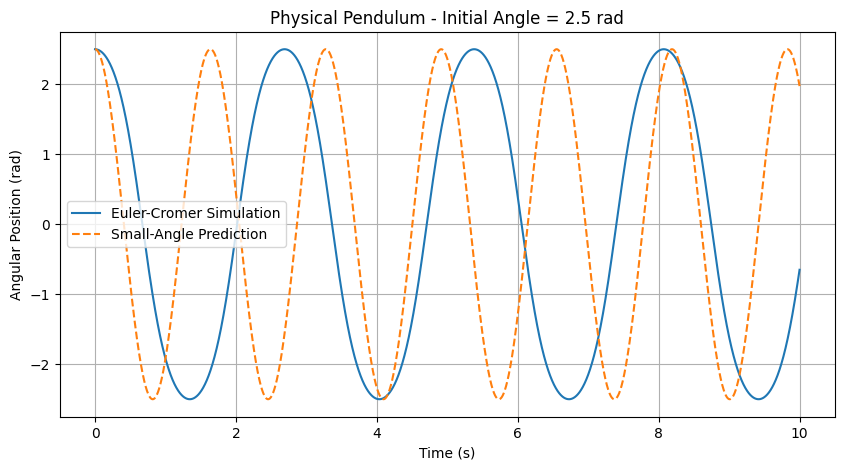

PART A - PHYSICAL PENDULUM RESULTS
-------------------------------------------------------
Rod mass:                 1.00 kg
Rod length:               1.00 m
Moment of inertia:        0.333333 kg m^2

Small-angle frequency:    3.836014 rad/s
Small-angle period:       1.637947 s

Small initial angle:      0.30 rad
Large initial angle:      2.50 rad


In [11]:
# PART A - THE PHYSICAL PENDULUM

# A1. PHYSICAL CONSTANTS AND ROD PROPERTIES

m = 1.0       # mass of rod (kg)
L = 1.0       # length of rod (m)
g = 9.81      # gravitational acceleration (m/s^2)

# Distance from pivot to center of mass
d = L / 2

# Moment of inertia of a uniform rod about one end
I = (1/3) * m * L**2

# Small-angle angular frequency
Omega = np.sqrt(m * g * d / I)

# Small-angle period
T_small = 2 * np.pi / Omega

# A2. GRAVITATIONAL TORQUE FUNCTION

def torque(theta):
    """Calculate the gravitational torque on the rod."""

    return -m * g * d * np.sin(theta)

# A3. EULER-CROMER ROTATIONAL INTEGRATOR

def rotate_step(theta, omega, torque_value, I, dt):
    """Perform one Euler-Cromer integration step."""

    # Calculate angular acceleration
    alpha = torque_value / I

    # Update angular velocity first
    omega_new = omega + alpha * dt

    # Update angular position
    theta_new = theta + omega_new * dt

    return theta_new, omega_new

# A4. SMALL-ANGLE INITIAL CONDITIONS

theta0_small = 0.3
theta = theta0_small
omega = 0.0

dt = 0.001
n_steps = 10000

# Store initial conditions
theta_small = [theta]
omega_small = [omega]

# A5. SMALL-ANGLE SIMULATION

for _ in range(n_steps):

    # Calculate current torque
    tau = torque(theta)

    # Advance simulation by one Euler-Cromer step
    theta, omega = rotate_step(
        theta,
        omega,
        tau,
        I,
        dt
    )

    # Store angular position and velocity
    theta_small.append(theta)
    omega_small.append(omega)

# Convert lists into NumPy arrays
theta_small = np.array(theta_small)
omega_small = np.array(omega_small)

times = np.arange(n_steps + 1) * dt

# Calculate small-angle prediction
theta_small_prediction = (
    theta0_small * np.cos(Omega * times)
)

# A6. SMALL-ANGLE COMPARISON

plt.figure(figsize=(10, 5))

plt.plot(
    times,
    theta_small,
    label="Euler-Cromer Simulation"
)

plt.plot(
    times,
    theta_small_prediction,
    linestyle="--",
    label="Small-Angle Prediction"
)

plt.xlabel("Time (s)")
plt.ylabel("Angular Position (rad)")
plt.title("Physical Pendulum - Initial Angle = 0.3 rad")

plt.grid(True)
plt.legend()
plt.show()

# A7. LARGE-ANGLE INITIAL CONDITIONS

theta0_large = 2.5
theta = theta0_large
omega = 0.0

# Store initial conditions
theta_large = [theta]
omega_large = [omega]

# A8. LARGE-ANGLE SIMULATION

for _ in range(n_steps):

    # Calculate current torque
    tau = torque(theta)

    # Advance simulation by one Euler-Cromer step
    theta, omega = rotate_step(
        theta,
        omega,
        tau,
        I,
        dt
    )

    # Store angular position and velocity
    theta_large.append(theta)
    omega_large.append(omega)

# Convert lists into NumPy arrays
theta_large = np.array(theta_large)
omega_large = np.array(omega_large)

# Calculate small-angle prediction
theta_large_prediction = (
    theta0_large * np.cos(Omega * times)
)

# A9. LARGE-ANGLE COMPARISON

plt.figure(figsize=(10, 5))

plt.plot(
    times,
    theta_large,
    label="Euler-Cromer Simulation"
)

plt.plot(
    times,
    theta_large_prediction,
    linestyle="--",
    label="Small-Angle Prediction"
)

plt.xlabel("Time (s)")
plt.ylabel("Angular Position (rad)")
plt.title("Physical Pendulum - Initial Angle = 2.5 rad")

plt.grid(True)
plt.legend()
plt.show()

# A10. PHYSICAL PENDULUM RESULTS

print("PART A - PHYSICAL PENDULUM RESULTS")
print("-" * 55)

print(f"Rod mass:                 {m:.2f} kg")
print(f"Rod length:               {L:.2f} m")
print(f"Moment of inertia:        {I:.6f} kg m^2")

print()

print(
    f"Small-angle frequency:    "
    f"{Omega:.6f} rad/s"
)

print(
    f"Small-angle period:       "
    f"{T_small:.6f} s"
)

print()

print(
    f"Small initial angle:      "
    f"{theta0_small:.2f} rad"
)

print(
    f"Large initial angle:      "
    f"{theta0_large:.2f} rad"
)

## Part A Interpretation

For the small initial angle of 0.3 rad, the Euler-Cromer simulation closely follows that of the small-angle prediction. The two curves remain nearly aligned throughout the full simulation. 

For the larger initial angle of 2.5 rad, the numerical solution differs significantly from the small-angle prediciton. The simulation pedlum has a visibly longer period, which causes the two curves to quickly move out of phase. This is because the true restoring torque depends on sin(theta), which becomes smaller than theta itself at large angular displacements.

This behavior is consistent with the nonlinear pendulum that we studied in lab 3. In both these cases, increasing the oscillation amplitude causes the real period to increase, whereas the small-angle model assumes a constant period.

## Part B - The Rolling Race

In this part, we model three rigid bodies rolling without slipping down the same incline. This is done across a hoop, a solid disk, and a solid sphere.

Furthermore, we use the rolling acceleration relation for each shape and then simulate their motion down a ramp of fixed length. Finally, we compare their finishing times and track the translational kinetic energy, rotational kinetic energy, gravitational potential energy, and total mechanical energies for one of the rolling bodies. This is done in order to verify energy conservation and examine how the body's energy is split between translation and rotation.

PART B - ROLLING RACE RESULTS
-------------------------------------------------------
Sphere finishing time: 2.0430 s
Disk finishing time:   2.1140 s
Hoop finishing time:   2.4410 s

Finishing order:
1. Sphere
2. Disk
3. Hoop


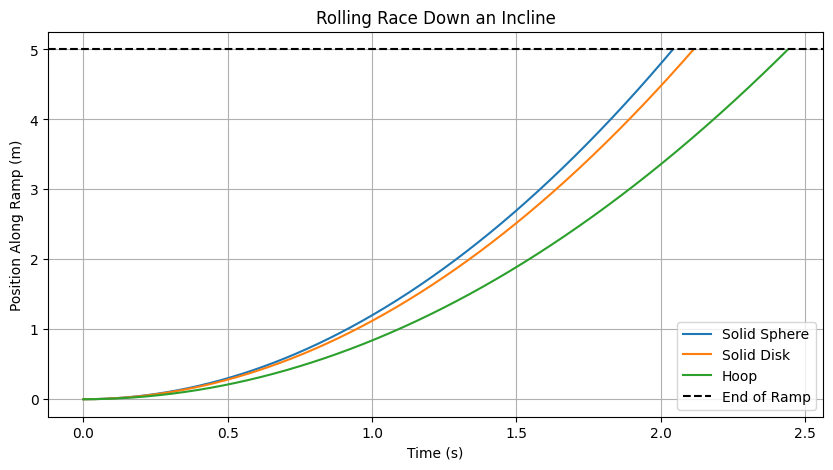

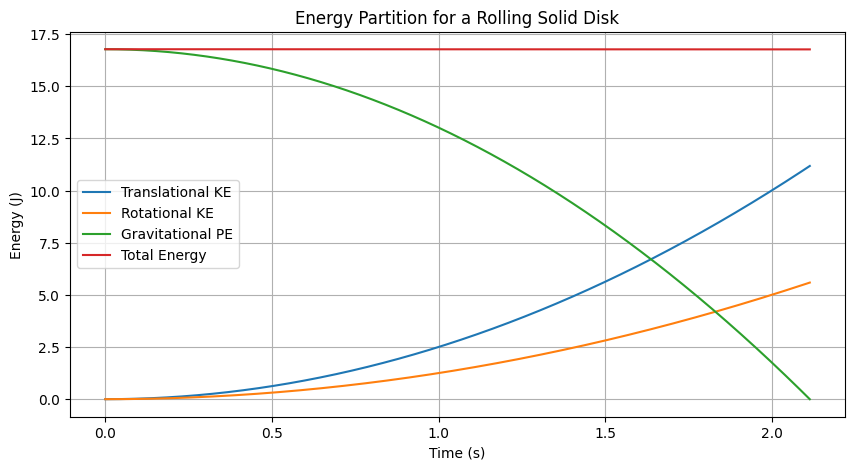


ENERGY CONSERVATION RESULTS
-------------------------------------------------------
Initial total energy: 16.77608803 J
Final total energy:   16.76815526 J
Maximum fractional energy error: 4.728620e-04

FINAL KINETIC ENERGY PARTITION
-------------------------------------------------------
Translational KE fraction: 0.6667
Rotational KE fraction:    0.3333

ROLLING ACCELERATIONS
-------------------------------------------------------
Sphere acceleration: 2.3966 m/s^2
Disk acceleration:   2.2368 m/s^2
Hoop acceleration:   1.6776 m/s^2


In [12]:
# PART B - THE ROLLING RACE

# B1. ROLLING ACCELERATION FUNCTION

def rolling_accel(theta_incline, c, g=9.81):
    """Calculate the acceleration of a body rolling without slipping."""

    return g * np.sin(theta_incline) / (1 + c)

# B2. ROLLING SIMULATION FUNCTION

def simulate_roll(c, ramp_length, theta_incline, dt=0.001):
    """Simulate a rolling body moving down an incline."""

    # Initial conditions
    x = 0.0
    v = 0.0
    t = 0.0

    # Constant acceleration for the selected body
    a = rolling_accel(theta_incline, c)

    # Store initial values
    times = [t]
    positions = [x]
    velocities = [v]

    # Continue until the body reaches the end of the ramp
    while x < ramp_length:

        # Update velocity
        v = v + a * dt

        # Update position using Euler-Cromer
        x = x + v * dt

        # Update time
        t = t + dt

        # Store values
        times.append(t)
        positions.append(x)
        velocities.append(v)

    return (
        np.array(times),
        np.array(positions),
        np.array(velocities)
    )

# B3. RAMP AND BODY PARAMETERS

g = 9.81

theta_incline = np.radians(20.0)
ramp_length = 5.0

# Shape factors: c = I / (mR^2)
c_hoop = 1.0
c_disk = 0.5
c_sphere = 0.4

# B4. RUN THE ROLLING RACE

t_hoop, x_hoop, v_hoop = simulate_roll(
    c_hoop,
    ramp_length,
    theta_incline
)

t_disk, x_disk, v_disk = simulate_roll(
    c_disk,
    ramp_length,
    theta_incline
)

t_sphere, x_sphere, v_sphere = simulate_roll(
    c_sphere,
    ramp_length,
    theta_incline
)

# B5. FINISHING TIMES

time_hoop = t_hoop[-1]
time_disk = t_disk[-1]
time_sphere = t_sphere[-1]

print("PART B - ROLLING RACE RESULTS")
print("-" * 55)

print(f"Sphere finishing time: {time_sphere:.4f} s")
print(f"Disk finishing time:   {time_disk:.4f} s")
print(f"Hoop finishing time:   {time_hoop:.4f} s")

print()

print("Finishing order:")
print("1. Sphere")
print("2. Disk")
print("3. Hoop")

# B6. POSITION VS. TIME COMPARISON

plt.figure(figsize=(10, 5))

plt.plot(
    t_sphere,
    x_sphere,
    label="Solid Sphere"
)

plt.plot(
    t_disk,
    x_disk,
    label="Solid Disk"
)

plt.plot(
    t_hoop,
    x_hoop,
    label="Hoop"
)

plt.axhline(
    ramp_length,
    color="black",
    linestyle="--",
    label="End of Ramp"
)

plt.xlabel("Time (s)")
plt.ylabel("Position Along Ramp (m)")
plt.title("Rolling Race Down an Incline")

plt.grid(True)
plt.legend()
plt.show()

# B7. ENERGY PARTITION FOR THE SOLID DISK

m = 1.0
R = 0.25

# Moment of inertia of a solid disk
I_disk = 0.5 * m * R**2

# Height remaining above the bottom of the ramp
height_disk = (
    ramp_length - x_disk
) * np.sin(theta_incline)

# Angular velocity from rolling without slipping
omega_disk = v_disk / R

# Translational kinetic energy
KE_trans = 0.5 * m * v_disk**2

# Rotational kinetic energy
KE_rot = 0.5 * I_disk * omega_disk**2

# Gravitational potential energy
PE = m * g * height_disk

# Total mechanical energy
E_total = KE_trans + KE_rot + PE

# B8. ENERGY VS. TIME

plt.figure(figsize=(10, 5))

plt.plot(
    t_disk,
    KE_trans,
    label="Translational KE"
)

plt.plot(
    t_disk,
    KE_rot,
    label="Rotational KE"
)

plt.plot(
    t_disk,
    PE,
    label="Gravitational PE"
)

plt.plot(
    t_disk,
    E_total,
    label="Total Energy"
)

plt.xlabel("Time (s)")
plt.ylabel("Energy (J)")
plt.title("Energy Partition for a Rolling Solid Disk")

plt.grid(True)
plt.legend()
plt.show()

# B9. ENERGY CONSERVATION ANALYSIS

energy_error = np.abs(
    (E_total - E_total[0]) / E_total[0]
)

print()
print("ENERGY CONSERVATION RESULTS")
print("-" * 55)

print(f"Initial total energy: {E_total[0]:.8f} J")
print(f"Final total energy:   {E_total[-1]:.8f} J")

print(
    f"Maximum fractional energy error: "
    f"{np.max(energy_error):.6e}"
)

# B10. ENERGY FRACTION IN ROTATION

final_total_ke = KE_trans[-1] + KE_rot[-1]

rotation_fraction = (
    KE_rot[-1] / final_total_ke
)

translation_fraction = (
    KE_trans[-1] / final_total_ke
)

print()
print("FINAL KINETIC ENERGY PARTITION")
print("-" * 55)

print(
    f"Translational KE fraction: "
    f"{translation_fraction:.4f}"
)

print(
    f"Rotational KE fraction:    "
    f"{rotation_fraction:.4f}"
)

# B11. SHAPE ACCELERATIONS

a_sphere = rolling_accel(
    theta_incline,
    c_sphere
)

a_disk = rolling_accel(
    theta_incline,
    c_disk
)

a_hoop = rolling_accel(
    theta_incline,
    c_hoop
)

print()
print("ROLLING ACCELERATIONS")
print("-" * 55)

print(f"Sphere acceleration: {a_sphere:.4f} m/s^2")
print(f"Disk acceleration:   {a_disk:.4f} m/s^2")
print(f"Hoop acceleration:   {a_hoop:.4f} m/s^2")

## Part B Interpretation

The rolling race produced the expected finishing order of the sphere, disk, and hoop. The solid sphere finished first at approximately 2.043 s, followed by the solidn disk at 2.114 s, and finally the hoop at 2.441 s.

This order is determined by the shape factor c = I/(mR^2). the sphere has the smallest shape factor, naturally followed by the disk and then the hoop. In this way, smaller fractions of the object's respective energy are required to go into rotation. As a result, the sphere has the highest linear acceleration down the incline.

For the solid disk, the energy analysis demonstrates that the gravitational potential energy is converted into both translational and rotational kinetic energy as it rolls down the ramp. The total mechanical energy remains nearly constant, with a maxximum fractional error of 4.73e-4, which indicates that the numerical simulation conserved energy very well.

The final kinetic energy was split such that approximately 66.67 % was converted into tranlational and 33.33 % was rotational energy. This was consistent with the moment of intertia for a solid disk. 

The finishing order does not depend on either mass or radius. In the rolling acceleration equation, the moment of intertia caused both mass and the radius to cancel. Therefore, the acceleration depends strictly on gravity, the incline, and the body's shape factor.

## Part C - Angular Momentum Conservation

In this part, we model a torque-free spinning body whose moment of inertia is changed during the simulation.

Furthermore, we enforce conservation of angular momentum whilst reducing the moment of inertia. We then track the moment of inertia, angular velocity, angular momentum, and rotational kinetic energy vs. time. These results are then used to verify that angular momentum remains constant while angular velocity and kinetic energy increase as the moment of inertia decreases.

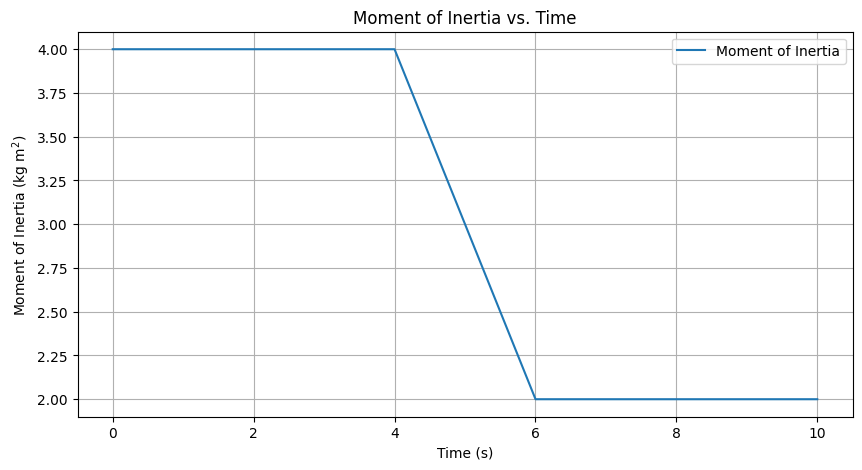

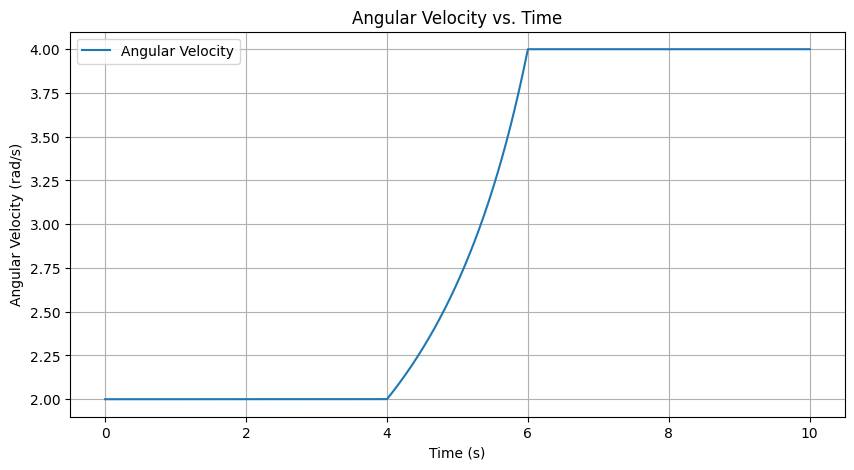

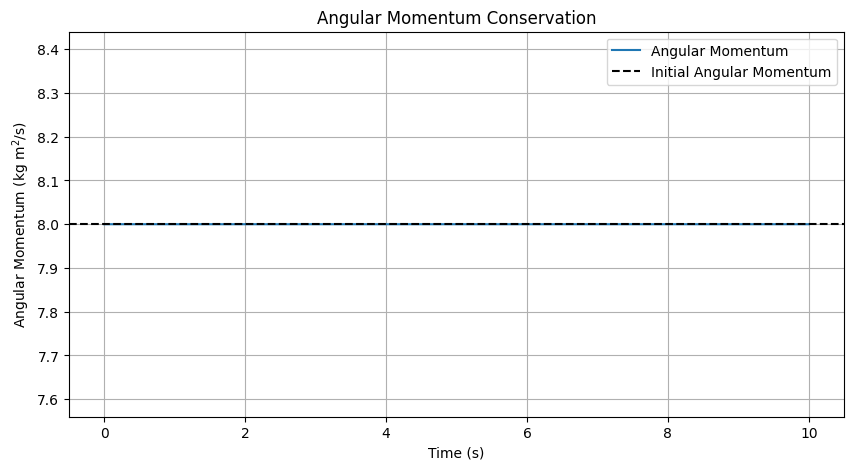

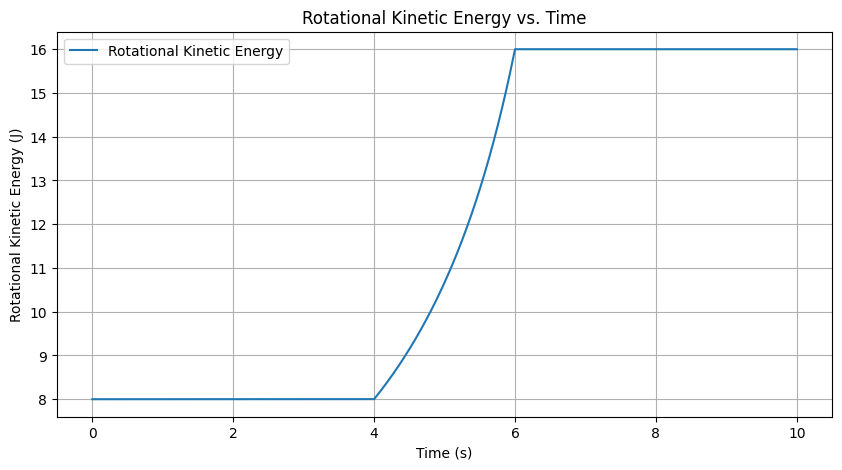

PART C - ANGULAR MOMENTUM RESULTS
-------------------------------------------------------
Initial moment of inertia:     4.0000 kg m^2
Final moment of inertia:       2.0000 kg m^2

Initial angular velocity:      2.0000 rad/s
Final angular velocity:        4.0000 rad/s

Initial angular momentum:      8.000000
Final angular momentum:        8.000000
Maximum fractional L error:   1.110223e-16

Initial rotational KE:         8.0000 J
Final rotational KE:           16.0000 J

Rotational KE increase:        8.0000 J


In [13]:
# PART C - ANGULAR MOMENTUM CONSERVATION

# C1. INITIAL CONDITIONS

I0 = 4.0          # initial moment of inertia (kg m^2)
omega0 = 2.0      # initial angular velocity (rad/s)

# Initial angular momentum
L0 = I0 * omega0

dt = 0.001
t_max = 10.0

times = np.arange(0, t_max + dt, dt)

# C2. MOMENT OF INERTIA FUNCTION

def moment_of_inertia(t):
    """Define how the moment of inertia changes with time."""

    # Initial moment of inertia before arms are pulled in
    if t < 4.0:
        return I0

    # Gradually reduce I from I0 to I0/2 between t = 4 and 6 s
    elif t <= 6.0:

        fraction = (t - 4.0) / 2.0

        return I0 - fraction * (I0 / 2.0)

    # Final moment of inertia after arms are pulled in
    else:
        return I0 / 2.0

# C3. STORAGE ARRAYS

moments = []
angular_velocities = []
angular_momenta = []
rotational_energies = []

# C4. TORQUE-FREE ROTATIONAL SIMULATION

for t in times:

    # Determine moment of inertia at this time
    I = moment_of_inertia(t)

    # Enforce conservation of angular momentum
    omega = L0 / I

    # Calculate angular momentum
    L = I * omega

    # Calculate rotational kinetic energy
    KE_rot = 0.5 * I * omega**2

    # Store values
    moments.append(I)
    angular_velocities.append(omega)
    angular_momenta.append(L)
    rotational_energies.append(KE_rot)

# Convert lists into NumPy arrays
moments = np.array(moments)
angular_velocities = np.array(angular_velocities)
angular_momenta = np.array(angular_momenta)
rotational_energies = np.array(rotational_energies)

# C5. MOMENT OF INERTIA VS. TIME

plt.figure(figsize=(10, 5))

plt.plot(
    times,
    moments,
    label="Moment of Inertia"
)

plt.xlabel("Time (s)")
plt.ylabel("Moment of Inertia (kg m$^2$)")
plt.title("Moment of Inertia vs. Time")

plt.grid(True)
plt.legend()
plt.show()

# C6. ANGULAR VELOCITY VS. TIME

plt.figure(figsize=(10, 5))

plt.plot(
    times,
    angular_velocities,
    label="Angular Velocity"
)

plt.xlabel("Time (s)")
plt.ylabel("Angular Velocity (rad/s)")
plt.title("Angular Velocity vs. Time")

plt.grid(True)
plt.legend()
plt.show()

# C7. ANGULAR MOMENTUM VS. TIME

plt.figure(figsize=(10, 5))

plt.plot(
    times,
    angular_momenta,
    label="Angular Momentum"
)

plt.axhline(
    L0,
    color="black",
    linestyle="--",
    label="Initial Angular Momentum"
)

plt.xlabel("Time (s)")
plt.ylabel("Angular Momentum (kg m$^2$/s)")
plt.title("Angular Momentum Conservation")

plt.grid(True)
plt.legend()
plt.show()

# C8. ROTATIONAL KINETIC ENERGY VS. TIME

plt.figure(figsize=(10, 5))

plt.plot(
    times,
    rotational_energies,
    label="Rotational Kinetic Energy"
)

plt.xlabel("Time (s)")
plt.ylabel("Rotational Kinetic Energy (J)")
plt.title("Rotational Kinetic Energy vs. Time")

plt.grid(True)
plt.legend()
plt.show()

# C9. ANGULAR MOMENTUM CONSERVATION ERROR

angular_momentum_error = np.abs(
    (angular_momenta - L0) / L0
)

print("PART C - ANGULAR MOMENTUM RESULTS")
print("-" * 55)

print(f"Initial moment of inertia:     {moments[0]:.4f} kg m^2")
print(f"Final moment of inertia:       {moments[-1]:.4f} kg m^2")

print()

print(f"Initial angular velocity:      {angular_velocities[0]:.4f} rad/s")
print(f"Final angular velocity:        {angular_velocities[-1]:.4f} rad/s")

print()

print(f"Initial angular momentum:      {angular_momenta[0]:.6f}")
print(f"Final angular momentum:        {angular_momenta[-1]:.6f}")

print(
    f"Maximum fractional L error:   "
    f"{np.max(angular_momentum_error):.6e}"
)

print()

print(f"Initial rotational KE:         {rotational_energies[0]:.4f} J")
print(f"Final rotational KE:           {rotational_energies[-1]:.4f} J")

print()

print(
    f"Rotational KE increase:        "
    f"{rotational_energies[-1] - rotational_energies[0]:.4f} J"
)

## Part C Interpretation

As the moment of inertia decreases from 4.0 to 2.0 kg*m^2, the angular velocity increases from 2.0 to 4.0 rad/s. This is because angular momentum was conserved, so a decrease in moment of inertia must be balanced by an increase in angular velocity.

The angular momentum remains essentially constant at 8.0 kg*m^2/s throughout the simulation. There was only a very small numerical error of 1.110e-16. This confirms that the model is correctly conserving angular momentum.

The rotational kinetic energy increases from 8.0 J to 16.0 J while the moment of inertia decreases. This does not go against any level of energy conservation because work must be done to change the body's mass distribution. 

In the skater example, work comes from the skater pulling their arms inward. This part also reinforces the usefulness of conservation laws as simulation checks. Energy conservation can help identify incorrect energy behavior, linear momentum conservation can help check collisions, and angular momentum conservation can help identify errors in rotational motion.